Hojas encontradas: ['Costos_Base', 'Tope_Escalado', 'Local_vs_API']


Proveedor,Modelo,Input_USD_1M,Output_USD_1M,Tipo
Google,Gemini 2.5 Flash,0.300,2.50,API pago
Google,Gemini 3 Pro,2.000,12.00,API pago
Anthropic,Claude Haiku 3.5,0.800,4.00,API pago
Anthropic,Claude Sonnet 4,3.000,15.00,API pago
Anthropic,Claude Opus 4.1,15.000,75.00,API pago
Amazon,Nova Micro,0.035,0.14,API pago
Amazon,Nova Lite,0.060,0.24,API pago
Meta,Llama 4 Scout LOCAL,0.000,0.00,Local Gratis - token $0
Google,Gemma 4 31B LOCAL,0.000,0.00,Local Gratis - token $0
Google,Gemma Servidor Propio Empresa,0.000,0.00,Local con infra propia - token $0 pero servidor $2500/mes


Modelo,Escenario,Costo_Tokens_USD
Amazon Nova Micro (API),2K proyecto,0.05
Amazon Nova Micro (API),2M,49.00
Amazon Nova Micro (API),2.000M (2B),49000.00
Gemini 2.5 Flash (API),2K proyecto,0.55
Gemini 2.5 Flash (API),2M,550.00
Gemini 2.5 Flash (API),2.000M (2B),550000.00
Claude Sonnet 4 (API),2K proyecto,4.50
Claude Sonnet 4 (API),2M,4500.00
Claude Sonnet 4 (API),2.000M (2B),4500000.00
Llama 4 Scout LOCAL,2K proyecto,0.00


Modalidad,Costo Token,Costo oculto,Observacion
Llama / Gemma Local en pc propio,0,Luz $ 15 - 30 / mes,Aplicable para caso de ejemplo
Gemma Servidor Propio Empresa,0,$2.500-4.000/mes (servidor + DevOps + energía),"Para escalar a 2B, token $0 pero se debe tener en cuenta gastos de mentenimiento de servidor manejo, etc"
API Pago,Variable,$0 no se responde por infra estructura de servidor,"Para 2B: $49K - $4.5M, cobra por cada token después del límite"


Modelo,Escenario,Costo_Tokens_USD
Llama 4 Scout LOCAL,2.000M (2B),0.0
Gemma Servidor Propio Empresa,2.000M (2B),0.0
Amazon Nova Micro (API),2.000M (2B),49000.0
Gemini 2.5 Flash (API),2.000M (2B),550000.0
Claude Sonnet 4 (API),2.000M (2B),4500000.0


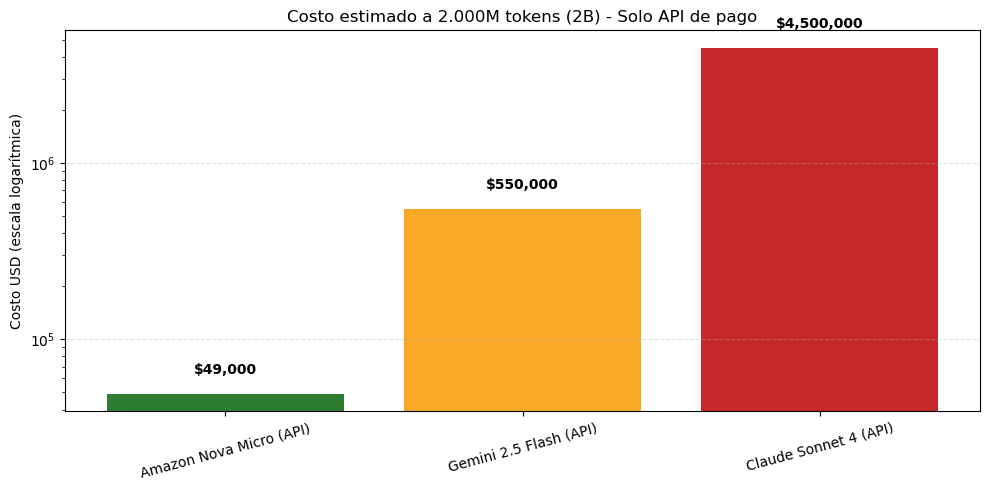

NOTA: Valores estimados con fines comparativos, calculados el 5 de noviembre de 2026 con precios públicos de lista.
Este gráfico compara COSTO, no CALIDAD. Nova es más económico para tareas simples. Claude es más costoso porque está diseñado para mayor razonamiento.


Modelo,Proveedor,Precio lista / 1M tokens,Verificar
Amazon Nova Micro,AWS Bedrock,$0.035 entrada / $0.14 salida,Ver en AWS
Claude Sonnet 4,Anthropic,$3 entrada / $15 salida,Ver en Anthropic
Gemini 2.5 Flash,Google AI,$0.30 entrada / $2.50 salida,Ver en Google
Llama 4 Scout / Gemma,Meta / Google - Abierto,"$0 token, costo es servidor propio",Ver Llama


Listo, archivo HTML creado para el jefe.


[NbConvertApp] Converting notebook Comparativo Costos.ipynb to html
[NbConvertApp] WARNING | Alternative text is missing on 1 image(s).
[NbConvertApp] Writing 353519 bytes to Comparativo Costos_para_el_jefe.html


In [8]:
#------------------------------------------------------------------------------------------------------
# Propósito: Presentar reportes informativos de costos correspondientes al uso de IA vía API 
#            o con uso de IA de forma local.
#            Esto con el ánimo de proyectar opciones para la toma de decisiones. 
#            Se aclara que los valores son estimados y que la toma de decisión 
#            no hace parte del análisis de los datos; es solo informativo para 
#            quienes deban tomar la decisión.
#------------------------------------------------------------------------------------------------------

import pandas as pd
from IPython.display import display, HTML

# 1. CARGA DEL ARCHIVO - Datos de costo.
archivo = "matriz_costos_Final.xlsx"
xls = pd.ExcelFile(archivo)
print("Hojas encontradas:", xls.sheet_names)

# Asignacion de hojas de archivo
df_base = pd.read_excel(archivo, sheet_name=0) # Hoja 1
df_tope = pd.read_excel(archivo, sheet_name=1)  # Hoja 2
df_local = pd.read_excel(archivo, sheet_name=2) # Hoja 3

# 2. FUNCION para definir titulos y resumen
def mostrar_con_resumen(df, titulo, resumen):
    html = f"""
    <div style='border:1px solid #ddd; border-radius:10px; padding:15px; margin-bottom:20px; background:#fafafa;'>
        <h3 style='margin:0; color:#1a73e8;'>{titulo}</h3>
        <p style='margin:5px 0 10px 0; color:#555; font-style:italic;'>{resumen}</p>
        <div style='height:320px; overflow:auto; background:white; border-radius:6px;'>
            {df.to_html(index=False)}
        </div>
    </div>
    """
    display(HTML(html))

# 3. MOSTRAR LAS 3 CON SU RESUMEN 
mostrar_con_resumen(df_base, 
    "1. Costos Base", 
    "Aquí están los costos fijos por cliente. Es la base para calcular todo lo demás.")

mostrar_con_resumen(df_tope, 
    "2. Tope Escalado - 2000 registros", 
    "Simulación de qué pasa si llegamos a 2000. Aquí se ve el tope donde ya no es rentable.")

mostrar_con_resumen(df_local, 
    "3. Local vs API - Costo Oculto", 
    "Comparativo del costo real si lo hacemos local vs pagando la API. Aquí está el ahorro oculto.")

# 4. COMPARATIVO 2B + GRÁFICA - Informe para el jefe
import matplotlib.pyplot as plt

# A. Tabla bonita solo del escenario 2B, ordenada


df_2b = df_tope[df_tope['Escenario'] == '2.000M (2B)'].sort_values('Costo_Tokens_USD')

mostrar_con_resumen(df_2b,
    "4. Comparativo a escala 2.000M (2B) - 2.000 millones de tokens",
    "Aquí se ve la diferencia real. En proyecto chiquito todos valen casi $0, a 2B la diferencia es de $49 mil vs $4.5 millones.")

# Gráfica, de comparativo
plt.figure(figsize=(10, 5))
df_grafica = df_2b[df_2b['Costo_Tokens_USD'] > 0]
plt.bar(df_grafica['Modelo'], df_grafica['Costo_Tokens_USD'], color=['#2E7D32', '#F9A825', '#C62828'])
plt.yscale('log')
plt.title('Costo estimado a 2.000M tokens (2B) - Solo API de pago')
plt.ylabel('Costo USD (escala logarítmica)')
plt.xticks(rotation=15)
plt.grid(axis='y', linestyle='--', alpha=0.4)
for i, v in enumerate(df_grafica['Costo_Tokens_USD']):
    plt.text(i, v*1.3, f"${v:,.0f}", ha='center', fontweight='bold')
plt.tight_layout()
# Guardar la gráfica como archivo para GitHub
plt.savefig("grafica_2B.png", dpi=150, bbox_inches="tight")
plt.show()


print("NOTA: Valores estimados con fines comparativos, calculados el 5 de noviembre de 2026 con precios públicos de lista.")
print("Este gráfico compara COSTO, no CALIDAD. Nova es más económico para tareas simples. Claude es más costoso porque está diseñado para mayor razonamiento.")


# 5. TABLA SOPORTE - Informacion de donde fue extrados los costos reportados
from IPython.display import display, HTML

html_fuentes = """
<div style="border: 1px solid #ddd; border-radius: 10px; padding: 15px; background: #F8F9FA; font-family: sans-serif;">
<h3 style="margin-top:0;">Fuentes oficiales - Verifique usted mismo</h3>
<p style="font-size:13px; color:#555;">Precios públicos de lista consultados el <b>5 de noviembre de 2026</b>. Si el precio cambió hoy, es porque el proveedor lo cambió.</p>
<table style="width:100%; border-collapse: collapse; font-size:14px;">
<tr style="background:#1A237E; color:white;">
  <th style="padding:10px; text-align:left;">Modelo</th>
  <th style="padding:10px; text-align:left;">Proveedor</th>
  <th style="padding:10px; text-align:left;">Precio lista / 1M tokens</th>
  <th style="padding:10px; text-align:left;">Verificar</th>
</tr>
<tr>
  <td style="padding:10px; border-bottom:1px solid #ddd;">Amazon Nova Micro</td>
  <td style="padding:10px; border-bottom:1px solid #ddd;">AWS Bedrock</td>
  <td style="padding:10px; border-bottom:1px solid #ddd;">$0.035 entrada / $0.14 salida</td>
  <td style="padding:10px; border-bottom:1px solid #ddd;"><a href="https://aws.amazon.com/bedrock/pricing/" target="_blank">Ver en AWS</a></td>
</tr>
<tr style="background:#E8EAF6;">
  <td style="padding:10px; border-bottom:1px solid #ddd;">Claude Sonnet 4</td>
  <td style="padding:10px; border-bottom:1px solid #ddd;">Anthropic</td>
  <td style="padding:10px; border-bottom:1px solid #ddd;">$3 entrada / $15 salida</td>
  <td style="padding:10px; border-bottom:1px solid #ddd;"><a href="https://www.anthropic.com/pricing" target="_blank">Ver en Anthropic</a></td>
</tr>
<tr>
  <td style="padding:10px; border-bottom:1px solid #ddd;">Gemini 2.5 Flash</td>
  <td style="padding:10px; border-bottom:1px solid #ddd;">Google AI</td>
  <td style="padding:10px; border-bottom:1px solid #ddd;">$0.30 entrada / $2.50 salida</td>
  <td style="padding:10px; border-bottom:1px solid #ddd;"><a href="https://ai.google.dev/gemini-api/docs/pricing" target="_blank">Ver en Google</a></td>
</tr>
<tr style="background:#E8EAF6;">
  <td style="padding:10px;">Llama 4 Scout / Gemma</td>
  <td style="padding:10px;">Meta / Google - Abierto</td>
  <td style="padding:10px;">$0 token, costo es servidor propio</td>
  <td style="padding:10px;"><a href="https://www.llama.com/" target="_blank">Ver Llama</a></td>
</tr>
</table>
<p style="font-size:12px; color:#777; margin-top:10px;">Nota: Valores estimados con fines comparativos. No incluye descuentos por batch, caché, impuestos ni costos de infraestructura.</p>
</div>
"""
display(HTML(html_fuentes))

# 6. EXPORTAR PARA EL JEFE
# Corre esto al final, cuando ya todo se vea bonito
# Le crea un archivo costos_api_para_el_jefe.html en la misma carpeta
# Ese sí se ve idéntico, con colores y links que funcionan

!jupyter nbconvert --to html "Comparativo Costos.ipynb" --output "Comparativo Costos_para_el_jefe.html"
print("Listo, archivo HTML creado para el jefe.")
